## 03 · Signatures

Gast / pSom / Crest module scores (union control pool) on the malignant manifold. Deliverable panels show **raw** per-cell scores (graph-smoothing aided the geography read in 02 but the deliverable is raw). Display uses the pseudotime-aligned diffusion basis from 02.

**Gate 2:** a single collapsed developmental axis — pSom/Gast developmental origin with Crest as the inverse terminal gradient (pSom↔Crest strongly anti-correlated), Gast diffuse and weakly co-repressive with no separate arm -> **GO (non-branching)**. No Gast/pSom bifurcation -> **Gate 3 NA**.

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars'); pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation', 'pSom':'Somitogenesis', 'Crest':'Neural Crest'}
print('cells:', adata.shape[0], '| scores present:', [m for m in modules if m in adata.obs])
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src, lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print('%s: %d/%d genes present' % (lab, g.size, feat[src].size))

cells: 65519 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 78/81 genes present
pSom: 93/98 genes present
Crest: 104/104 genes present


In [4]:
print('smoothed spatial correlations (geography):')
for a, b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print('  %s vs %s: r = %+.2f' % (a, b, np.corrcoef(adata.obs[a], adata.obs[b])[0,1]))
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for sname in ['Gast_sm','pSom_sm','Crest_sm']:
    rho, _ = spearmanr(t, adata.obs[sname]); print('  %s: rho = %+.3f' % (sname, rho))
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
ph = adata.obs['pSom_sm'] >= adata.obs['pSom_sm'].quantile(0.9)
print('pSom-high decile mean pseudotime = %.2f (origin)' % tn[ph.values].mean())
print('Crest-high decile mean pseudotime = %.2f (terminal)' % tn[hi.values].mean())
print('global module means (raw):', {m: round(float(adata.obs[m].mean()),3) for m in ['Gast','pSom','Crest']})
print('GATE 2: shared pSom/Gast origin + inverse terminal Crest -> GO (non-branching)')
print('GATE 3: no Gast/pSom cross-repression arm (Gast negative at every tip) -> NA')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.22
  Crest_sm vs Gast_sm: r = -0.24
  Crest_sm vs pSom_sm: r = -0.82
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.213
  pSom_sm: rho = -0.209
  Crest_sm: rho = +0.255
pSom-high decile mean pseudotime = 0.28 (origin)
Crest-high decile mean pseudotime = 0.73 (terminal)
global module means (raw): {'Gast': -0.014, 'pSom': 0.022, 'Crest': -0.005}
GATE 2: shared pSom/Gast origin + inverse terminal Crest -> GO (non-branching)
GATE 3: no Gast/pSom cross-repression arm (Gast negative at every tip) -> NA


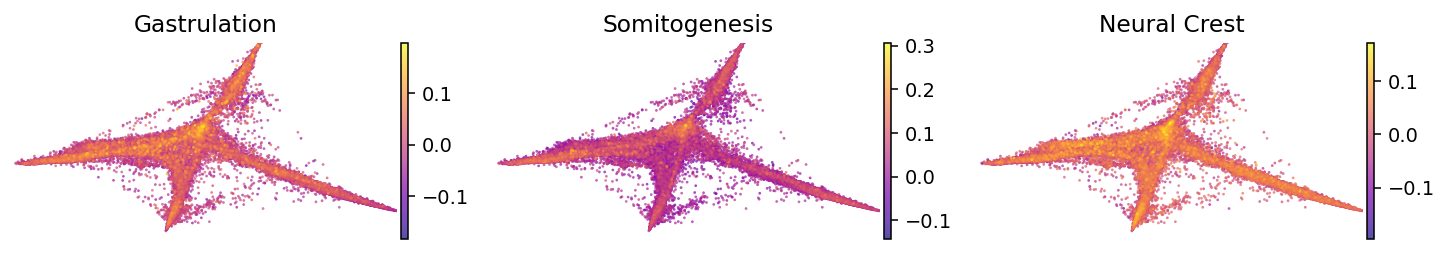

In [5]:
# overview: raw signatures side by side on the pseudotime-aligned diffusion display
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo, yhi = np.percentile(xl[:,1],[0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, axes = plt.subplots(1, 3, figsize=(10.5,1.9))
for ax, (m, title) in zip(axes, modules.items()):
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=8, colorbar_loc='right',
               frameon=False, show=False, ax=ax, title=title)
    ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
fig.tight_layout(); plt.show()

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


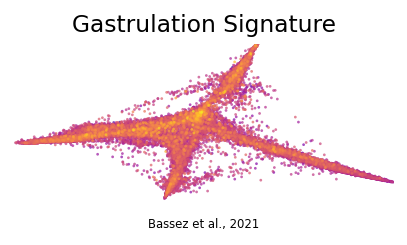

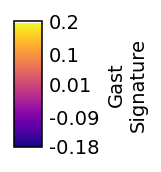

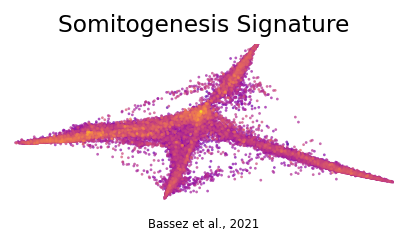

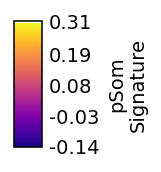

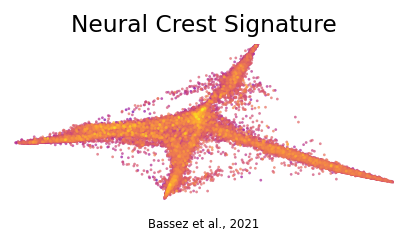

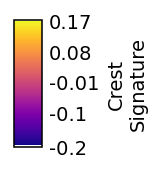

In [6]:
# save the three signature deliverables (raw scores) + external colorbars, house (3.5,1.5) aspect
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo, yhi = np.percentile(xl[:,1],[0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=8, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
    ax.text(.5, -.14, 'Bassez et al., 2021', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, '%s_signature.pdf' % m), bbox_inches='tight')
    lo, hi = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label('%s\nSignature' % m); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, '%s_colorbar.pdf' % m), bbox_inches='tight')
    plt.show()
    print('saved %s_signature.pdf + colorbar' % m)

In [7]:
for _c in adata.obs.columns:
    if adata.obs[_c].dtype == object: adata.obs[_c] = adata.obs[_c].astype(str)
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (65519, 22208)
